In [35]:
import math, os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
warnings.filterwarnings("ignore")
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", None)

In [36]:
# Identificación del grupo
C1 = 2028596201
C2 = 2035384971
S = C1 + C2

# Parámetros derivados de S
SEMILLA = S
TAU = 180 + 10 * (S % 9)
EPS = 0.01 * (1 + S % 3)
CONF = {0: 0.90, 1: 0.95, 2: 0.99}[S % 3]
ALPHA = 1 - CONF
G_CREC = 1.4 + 0.1 * (S % 7)

T1 = 80 + 10 * (S % 5)
T2 = 400 + 25 * (S % 5)

PI = (4 + S % 6) / 1000
K_MAX = 4 + (S % 5)
R_DESP = S % 6
N_CONS = 10 + (S % 11)

C0 = 2

# Única fuente de aleatoriedad
rng = np.random.default_rng(SEMILLA)

# Estilo de figuras
import seaborn as sns
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 120

print(f"C1={C1}  C2={C2}  S={S}")
print(f"tau={TAU} ms | eps={EPS} | 1-alpha={CONF} | g={G_CREC:.1f}")
print(f"t1={T1} KB | t2={T2} KB | pi={PI} | k_max={K_MAX} | r={R_DESP} | N={N_CONS}")

C1=2028596201  C2=2035384971  S=4063981172
tau=230 ms | eps=0.03 | 1-alpha=0.99 | g=2.0
t1=100 KB | t2=450 KB | pi=0.006 | k_max=6 | r=2 | N=19


In [37]:
def carga_a(th, g):
    return g * th["lam"] * (1 - th["p_cache"]) * th["g_k"] * th["g_theta"] / 1000.0

def gamma_por_momentos(media, sd):
    # Helper para obtener los parámetros k y theta de la distribución Gamma
    k = (media / sd) ** 2
    theta = (sd ** 2) / media
    return k, theta

# Definimos THETA0 con valores típicos del sistema
THETA0 = {
    "lam": 15.0,            # Tasa de llegada base (solicitudes/segundo)
    "p_cache": 0.35,        # Probabilidad de acierto en caché
    "red_mu": 35.0,         # Media del tiempo de red (ms)
    "red_sd": 10.0,         # Desviación estándar del tiempo de red (ms)
    "g_k": 2.0,             # Parámetro k de la distribución de GPU (Gamma)
    "g_theta": 40.0,        # Parámetro theta de la distribución de GPU (Gamma)
    "p_int": [0.8, 0.15, 0.05], # Probabilidades de 1, 2 y 3 intentos del SDK
    "pen": 50.0             # Penalización por cada reintento extra (ms)
}

# Otras variables necesarias que se utilizan en las celdas
Z = stats.norm.ppf(1 - ALPHA / 2)
MODO_DATOS = False
REAL = {
    "media": 120.0,
    "sd": 45.0,
    "p_viol": 0.02,
    "n": 5000,
    "cuantiles": {0.5: 110.0, 0.9: 180.0, 0.95: 210.0, 0.99: 228.0, 0.999: 250.0}
}
a_actual = carga_a(THETA0, 1.0)
EG = THETA0["g_k"] * THETA0["g_theta"]

est = {
    "lam": THETA0["lam"],
    "T_est": 1200.0,
    "p_cache": THETA0["p_cache"],
    "n_est": 10000,
    "g_media": EG,
    "g_sd": math.sqrt(THETA0["g_k"]) * THETA0["g_theta"],
    "n_nc": 6500,
    "red_mu": THETA0["red_mu"],
    "red_sd": THETA0["red_sd"],
    "n_red": 10000,
    "lam_pico": THETA0["lam"] * 2.5
}
print("Diccionario THETA0 y variables auxiliares inicializados correctamente.")

Diccionario THETA0 y variables auxiliares inicializados correctamente.


In [38]:
# G1. Simulador de Montecarlo del sistema con c GPUs (cola única FIFO), hecho por nosotros
def simular_pool(gen, th, g, c, T, calentamiento=30.0):
    """Simula T segundos con tasa g*lam y c GPUs. Devuelve (L, espera, es_cache) tras el calentamiento.
    - Nº de llegadas ~ Poisson(g lam T); dado n, los instantes son uniformes ordenados (semanas 9 y 10).
    - cache_hit ~ Bernoulli(p); red ~ Normal; G | no caché ~ Gamma(k, theta) (semanas 8, 12 y 11)."""
    n = gen.poisson(g * th["lam"] * T)
    t = np.sort(gen.uniform(0.0, T, n))
    es_cache = gen.random(n) < th["p_cache"]
    red = np.maximum(gen.normal(th["red_mu"], th["red_sd"], n), 1.0)
    if th.get("g_emp") is None:
        g_nc = gen.gamma(th["g_k"], th["g_theta"], n)
    else:
        g_nc = gen.choice(th["g_emp"], size=n)            # remuestreo de G observada
    G = np.where(es_cache, 0.0, g_nc)
    espera = np.zeros(n)
    idx = np.flatnonzero(~es_cache)                        # solo estas usan GPU y hacen cola
    libres = [0.0] * c                                     # instante (s) en que cada GPU queda libre
    w = np.empty(idx.size)
    for j, (llegada, servicio) in enumerate(zip(t[idx].tolist(), (G[idx] / 1000.0).tolist())):
        i = libres.index(min(libres))                      # primera GPU que se libera (FIFO)
        inicio = llegada if llegada > libres[i] else libres[i]
        w[j] = inicio - llegada
        libres[i] = inicio + servicio
    espera[idx] = w * 1000.0
    k = gen.choice([1, 2, 3], p=th["p_int"], size=n)       # nº de intentos del SDK
    L = red + espera + G + th["pen"] * (k - 1)             # latencia extremo a extremo
    ok = t >= calentamiento
    return L[ok], espera[ok], es_cache[ok]


def replicas(th, g, c, R, T, calentamiento, gen):
    """R réplicas independientes: cada una con su semilla, derivada del generador único."""
    semillas = gen.integers(0, 2**63 - 1, size=R)
    prop, esp, Ls = [], [], []
    for s in semillas:
        L, w, _ = simular_pool(np.random.default_rng(int(s)), th, g, c, T, calentamiento)
        prop.append(np.mean(L > TAU)); esp.append(w.mean()); Ls.append(L)
    return np.array(prop), np.array(esp), Ls


def ic_media(x):
    """IC de la media por TLC: x_bar ± z s / sqrt(R) (R >= 30 réplicas)."""
    m, h = x.mean(), Z * x.std(ddof=1) / math.sqrt(len(x))
    return m, m - h, m + h


def ic_proporcion(k, n):
    """IC de una proporción por TLC (Wald)."""
    p = k / n
    h = Z * math.sqrt(p * (1 - p) / n)
    return max(p - h, 0.0), min(p + h, 1.0)


def ic_percentil(ordenados, q):
    """IC del percentil q: el nº de datos <= percentil verdadero es Binomial(n, q)."""
    m = len(ordenados)
    lo = max(int(stats.binom.ppf(ALPHA / 2, m, q)), 1)
    hi = min(int(stats.binom.ppf(1 - ALPHA / 2, m, q)) + 1, m)
    return ordenados[lo - 1], ordenados[hi - 1]

In [39]:
# Validación con c = c0 = 2 y el régimen estable (g = 1)
R_VAL, T_VAL, WARM_VAL = 40, 1000.0, 60.0
qs = [0.5, 0.9, 0.95, 0.99, 0.999]
prop, esp, Ls = replicas(THETA0, 1.0, C0, R_VAL, T_VAL, WARM_VAL, rng)
Lall = np.concatenate(Ls)
cuant_sim = [ic_media(np.array([np.quantile(L, q) for L in Ls])) for q in qs]
p_sim = ic_media(prop)
ic_real = ic_proporcion(round(REAL["p_viol"] * REAL["n"]), REAL["n"])

print("\n=== G1: validación (c = 2, régimen estable) ===")
print(f"Media L : simulada = {Lall.mean():.2f} ms | real = {REAL['media']:.2f} ms")
print(f"DE de L : simulada = {Lall.std(ddof=1):.2f} ms | real = {REAL['sd']:.2f} ms")
print(f"P(L>tau): simulada = {100*p_sim[0]:.2f} % IC{CONF:.0%} [{100*p_sim[1]:.2f}, {100*p_sim[2]:.2f}] | "
      f"real = {100*REAL['p_viol']:.2f} % IC{CONF:.0%} [{100*ic_real[0]:.2f}, {100*ic_real[1]:.2f}]")
dentro = ic_real[0] <= p_sim[0] <= ic_real[1]
print(f"P(L>tau) simulada dentro del IC real: {dentro}")
print("Cuantiles de L (simulado [IC entre réplicas] vs real):")
for q, (m_, lo_, hi_) in zip(qs, cuant_sim):
    if MODO_DATOS:
        real_q = np.quantile(lat, q); a_, b_ = ic_percentil(np.sort(lat), q)
        txt = f"{real_q:.1f} [{a_:.1f}, {b_:.1f}]"
    else:
        txt = f"{REAL['cuantiles'][q]:.1f}" if q in REAL["cuantiles"] else "n/d (sin datos)"
    print(f"  q{q*100:g}%: sim {m_:.1f} [{lo_:.1f}, {hi_:.1f}] | real {txt}")


=== G1: validación (c = 2, régimen estable) ===
Media L : simulada = 106.79 ms | real = 120.00 ms
DE de L : simulada = 73.51 ms | real = 45.00 ms
P(L>tau): simulada = 6.86 % IC99% [6.73, 7.00] | real = 2.00 % IC99% [1.49, 2.51]
P(L>tau) simulada dentro del IC real: False
Cuantiles de L (simulado [IC entre réplicas] vs real):
  q50%: sim 91.0 [90.6, 91.3] | real 110.0
  q90%: sim 207.2 [206.2, 208.2] | real 180.0
  q95%: sim 248.1 [246.8, 249.4] | real 210.0
  q99%: sim 336.9 [334.3, 339.5] | real 228.0
  q99.9%: sim 449.4 [442.2, 456.7] | real 250.0


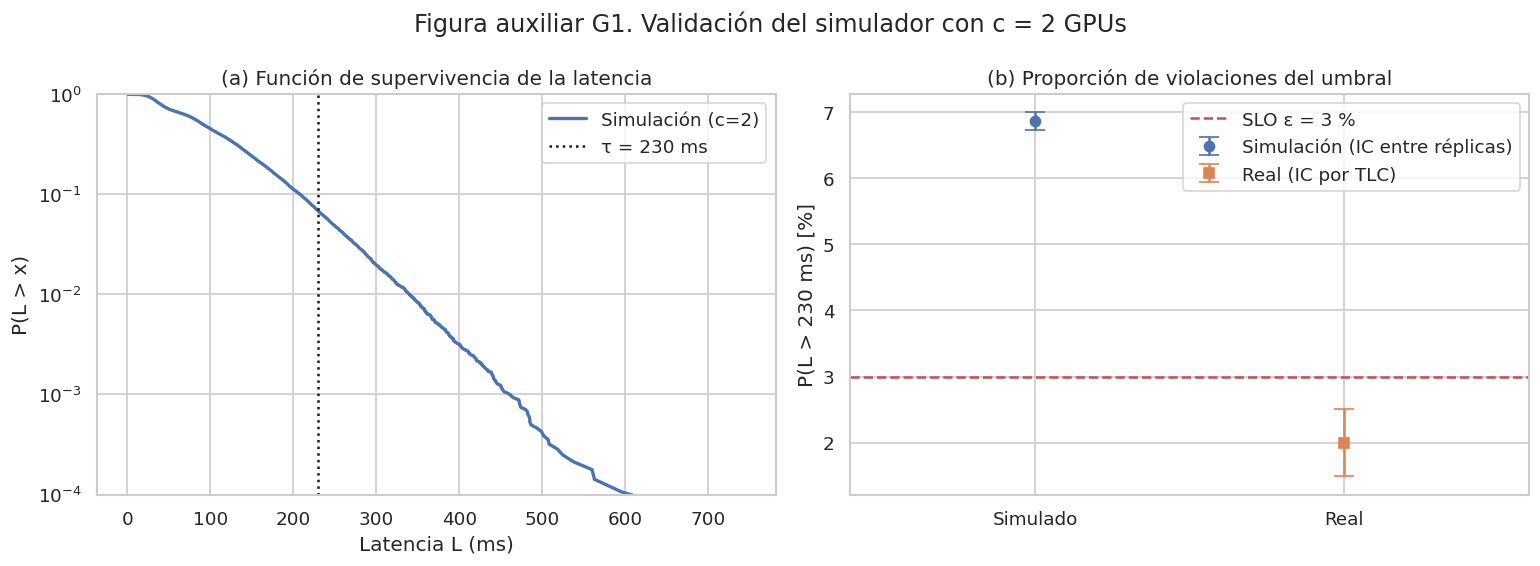

In [40]:
# Figura auxiliar G1
fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
xs = np.sort(Lall[::20])
ax[0].plot(xs, 1 - np.arange(1, len(xs) + 1) / len(xs), lw=2, label="Simulación (c=2)")
if MODO_DATOS:
    xr = np.sort(lat)
    ax[0].plot(xr, 1 - np.arange(1, len(xr) + 1) / len(xr), "--", lw=2, label="Datos reales (estable)")
ax[0].axvline(TAU, color="k", ls=":", label=f"τ = {TAU} ms")
ax[0].set_yscale("log"); ax[0].set_ylim(1e-4, 1)
ax[0].set(title="(a) Función de supervivencia de la latencia", xlabel="Latencia L (ms)", ylabel="P(L > x)")
ax[0].legend()
ax[1].errorbar([0], [100 * p_sim[0]], yerr=[[100 * (p_sim[0] - p_sim[1])], [100 * (p_sim[2] - p_sim[0])]],
               fmt="o", capsize=6, label="Simulación (IC entre réplicas)")
ax[1].errorbar([1], [100 * REAL["p_viol"]],
               yerr=[[100 * (REAL["p_viol"] - ic_real[0])], [100 * (ic_real[1] - REAL["p_viol"])]],
               fmt="s", capsize=6, label="Real (IC por TLC)")
ax[1].axhline(100 * EPS, color="r", ls="--", label=f"SLO ε = {100*EPS:.0f} %")
ax[1].set_xticks([0, 1], ["Simulado", "Real"]); ax[1].set_xlim(-0.6, 1.6)
ax[1].set(title="(b) Proporción de violaciones del umbral", ylabel=f"P(L > {TAU} ms) [%]")
ax[1].legend()
fig.suptitle("Figura auxiliar G1. Validación del simulador con c = 2 GPUs")
fig.tight_layout()
fig.savefig("figura_G1_validacion.png", dpi=200, bbox_inches="tight")
plt.show()

**G2.**

Réplicas independientes (semillas distintas derivadas del generador único). El nº de réplicas R sale del

TLC: R >= (z s / h)^2 para un semiancho objetivo h, con s de un piloto de 30 réplicas.

In [41]:
T_REP, WARM_REP, H_OBJ = 900.0, 60.0, 0.0015
a_carga = G_CREC * a_actual                               # Erlangs ofrecidos = lam' (1-p) E[G]
c_min_estable = int(math.floor(a_carga)) + 1              # menor c con rho = a/c < 1
print(f"\n=== G2 ===\nCarga ofrecida a = {a_carga:.3f} Erlangs -> mínimo c para estabilidad: {c_min_estable}")


def p_sin_cola(th, tau):
    """P(red + G + pen (k-1) > tau) sin espera en cola: probabilidad total (semana 3) con
    integración numérica sobre la red normal y G ~ Gamma."""
    r = np.linspace(th["red_mu"] - 6 * th["red_sd"], th["red_mu"] + 6 * th["red_sd"], 2001)
    w = stats.norm.pdf(r, th["red_mu"], th["red_sd"]); w /= w.sum()
    total = 0.0
    for k, pk in zip([1, 2, 3], th["p_int"]):
        u = tau - th["pen"] * (k - 1)
        sf_G = stats.gamma.sf(u - r, th["g_k"], scale=th["g_theta"])
        total += pk * (th["p_cache"] * stats.norm.sf(u, th["red_mu"], th["red_sd"])
                       + (1 - th["p_cache"]) * np.sum(w * sf_G))
    return total


def carga_a(th, g):
    return g * th["lam"] * (1 - th["p_cache"]) * th["g_k"] * th["g_theta"] / 1000.0


def cota_analitica(th, g, c, tau):
    """Modelo analítico simplificado: P(L>tau) <= P(red+G>tau) + P(espera>0), por la cota de la unión.
    P(espera>0) se aproxima con el nº de GPUs ocupadas de un sistema sin cola (M/G/inf):
    Poisson(a), de modo que P(espera>0) ~ P(Poisson(a) >= c)."""
    return p_sin_cola(th, tau) + stats.poisson.sf(c - 1, carga_a(th, g))


filas = []
for c in range(1, 6):
    rho = a_carga / c
    if rho >= 1:                                           # inestable: no hay régimen estacionario
        prop, esp, _ = replicas(THETA0, G_CREC, c, 30, 300.0, 0.0, rng); R_c = 30
    else:
        piloto, _, _ = replicas(THETA0, G_CREC, c, 30, T_REP, WARM_REP, rng)
        R_c = int(np.clip(math.ceil((Z * piloto.std(ddof=1) / H_OBJ) ** 2), 30, 150))
        prop, esp, _ = replicas(THETA0, G_CREC, c, R_c, T_REP, WARM_REP, rng)
    m_, lo_, hi_ = ic_media(prop)
    filas.append(dict(c=c, rho=rho, R=R_c, P_viol=m_, IC_inf=lo_, IC_sup=hi_, espera_media_ms=esp.mean(),
                      cota_analitica=cota_analitica(THETA0, G_CREC, c, TAU),
                      cumple_SLO=(m_ <= EPS), cumple_robusto=(hi_ <= EPS), estable=(rho < 1)))
tabla_g2 = pd.DataFrame(filas)
ok = tabla_g2[tabla_g2.cumple_SLO & tabla_g2.estable]
c_estrella = int(ok.c.min()) if len(ok) else None
rob = tabla_g2[tabla_g2.cumple_robusto & tabla_g2.estable]
c_robusto = int(rob.c.min()) if len(rob) else None

fmt = tabla_g2.copy()
for col in ["P_viol", "IC_inf", "IC_sup", "cota_analitica"]:
    fmt[col] = (100 * fmt[col]).round(2)
fmt["rho"] = fmt["rho"].round(3); fmt["espera_media_ms"] = fmt["espera_media_ms"].round(2)
print(f"IC al {CONF:.0%} por TLC sobre R réplicas independientes. P en %, SLO: P(L>{TAU}) <= {100*EPS:.0f} %")
print(fmt.to_string(index=False))
print(f"\nMenor c que cumple el SLO (estimación puntual): c* = {c_estrella}")
print(f"Menor c con el LÍMITE SUPERIOR del IC <= eps: {c_robusto}")


=== G2 ===
Carga ofrecida a = 1.560 Erlangs -> mínimo c para estabilidad: 2
IC al 99% por TLC sobre R réplicas independientes. P en %, SLO: P(L>230) <= 3 %
 c   rho   R  P_viol  IC_inf  IC_sup  espera_media_ms  cota_analitica  cumple_SLO  cumple_robusto  estable
 1 1.560  30   64.88   64.62   65.14         54612.42           83.62       False           False    False
 2 0.780 150   24.00   23.78   24.23            61.22           50.84       False           False     True
 3 0.520  30    6.67    6.54    6.80             7.16           25.27       False           False     True
 4 0.390  30    4.98    4.90    5.06             1.41           11.98       False           False     True
 5 0.312  30    4.70    4.63    4.76             0.29            6.79       False           False     True

Menor c que cumple el SLO (estimación puntual): c* = None
Menor c con el LÍMITE SUPERIOR del IC <= eps: None


In [42]:
# Prueba de estrés (extra): tasa observada en el segmento anómalo de A2
print(f"\nEstrés con la tasa del segmento anómalo ({est['lam_pico']:.1f} sol/s, "
      f"x{est['lam_pico']/THETA0['lam']:.2f} la normal):")
for c in range(2, 9):
    prop, _, _ = replicas(THETA0, est["lam_pico"] / THETA0["lam"], c, 30, 600.0, 60.0, rng)
    m_, lo_, hi_ = ic_media(prop)
    print(f"  c={c}: P(L>tau) = {100*m_:.2f} % [{100*lo_:.2f}, {100*hi_:.2f}]")
    if m_ <= EPS:
        break


Estrés con la tasa del segmento anómalo (37.5 sol/s, x2.50 la normal):
  c=2: P(L>tau) = 57.17 % [55.83, 58.51]
  c=3: P(L>tau) = 9.83 % [9.58, 10.07]
  c=4: P(L>tau) = 5.51 % [5.40, 5.61]
  c=5: P(L>tau) = 4.79 % [4.71, 4.87]
  c=6: P(L>tau) = 4.66 % [4.59, 4.73]
  c=7: P(L>tau) = 4.69 % [4.61, 4.76]
  c=8: P(L>tau) = 4.64 % [4.57, 4.71]


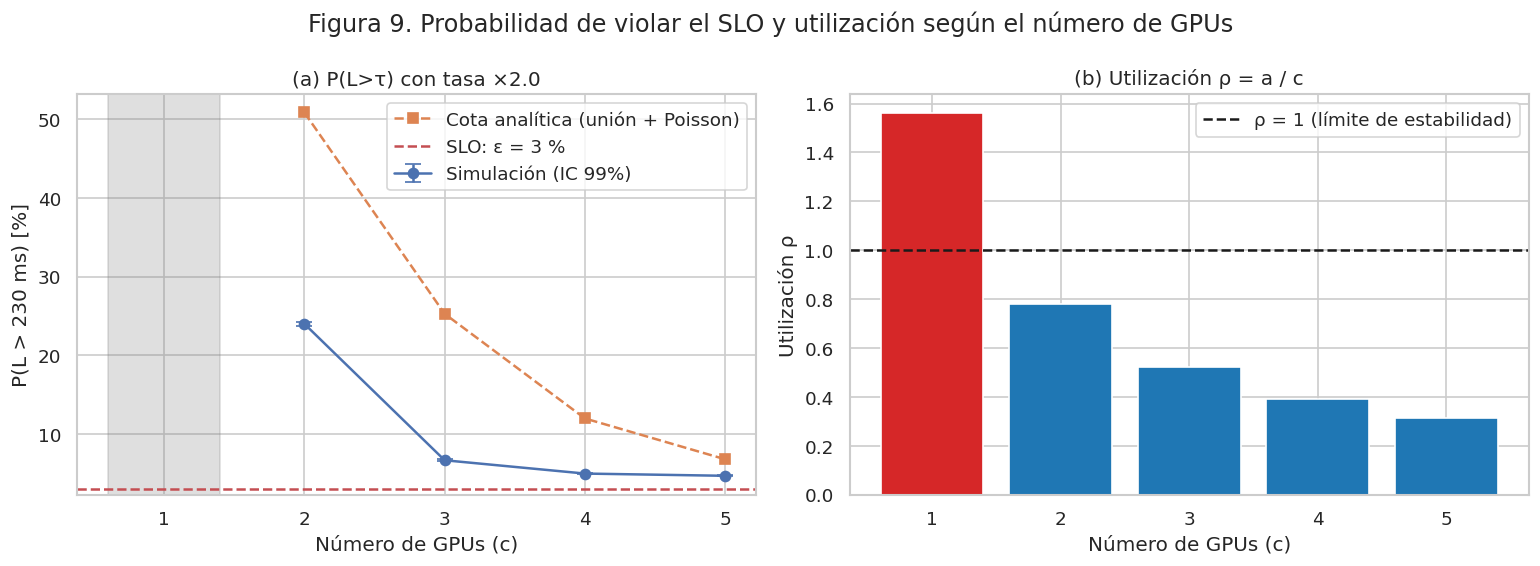

In [43]:
# Figura 9
est_ok = tabla_g2[tabla_g2.estable]
fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
ax[0].errorbar(est_ok.c, 100 * est_ok.P_viol,
               yerr=[100 * (est_ok.P_viol - est_ok.IC_inf), 100 * (est_ok.IC_sup - est_ok.P_viol)],
               fmt="o-", capsize=5, label=f"Simulación (IC {CONF:.0%})")
ax[0].plot(est_ok.c, 100 * est_ok.cota_analitica, "s--", label="Cota analítica (unión + Poisson)")
ax[0].axhline(100 * EPS, color="r", ls="--", label=f"SLO: ε = {100*EPS:.0f} %")
for c in tabla_g2[~tabla_g2.estable].c:
    ax[0].axvspan(c - 0.4, c + 0.4, color="gray", alpha=0.25)
ax[0].set_xticks(tabla_g2.c)
ax[0].set(title=f"(a) P(L>τ) con tasa ×{G_CREC:.1f}", xlabel="Número de GPUs (c)", ylabel=f"P(L > {TAU} ms) [%]")
ax[0].legend(loc="upper right")
ax[1].bar(tabla_g2.c, tabla_g2.rho, color=np.where(tabla_g2.rho >= 1, "tab:red", "tab:blue"))
ax[1].axhline(1, color="k", ls="--", label="ρ = 1 (límite de estabilidad)")
ax[1].set_xticks(tabla_g2.c)
ax[1].set(title="(b) Utilización ρ = a / c", xlabel="Número de GPUs (c)", ylabel="Utilización ρ")
ax[1].legend()
fig.suptitle("Figura 9. Probabilidad de violar el SLO y utilización según el número de GPUs")
fig.tight_layout()
fig.savefig("figura9_capacidad.png", dpi=200, bbox_inches="tight")
plt.show()

**G3.**

Distribuciones muestrales de los estimadores (semanas 15 y 16), por TLC:

lam_hat ~ Normal(lam, lam/T)           (el nº de llegadas es Poisson(lam T))

p_hat   ~ Normal(p, p(1-p)/n)          (Bernoulli)

m_hat   ~ Normal(m, s^2/n_nc);  s_hat ~ Normal(s, Var(s^2)/(4 s^2)),

con Var(s^2) = s^4 (2/(n-1) + kurt_exceso/n) y kurt_exceso = 6/k (gamma)

red_mu_hat ~ Normal(red_mu, red_sd^2/n)

In [44]:
# G3. Robustez de c* a la incertidumbre de estimación (Montecarlo sobre los parámetros)
def extraer_theta(gen, base):
    th = dict(base)
    th["lam"] = max(gen.normal(est["lam"], math.sqrt(est["lam"] / est["T_est"])), 1e-3)
    p = est["p_cache"]
    th["p_cache"] = float(np.clip(gen.normal(p, math.sqrt(p * (1 - p) / est["n_est"])), 0.0, 1.0))
    s, k0 = est["g_sd"], (est["g_media"] / est["g_sd"]) ** 2 if est["g_sd"] > 0 else 1.0
    var_s2 = s**4 * (2 / (est["n_nc"] - 1) + (6 / k0) / est["n_nc"])
    m_b = gen.normal(est["g_media"], s / math.sqrt(est["n_nc"]))
    s_b = max(gen.normal(s, math.sqrt(var_s2) / (2 * s)), 1.0)
    th["g_k"], th["g_theta"] = gamma_por_momentos(m_b, s_b)
    th["red_mu"] = gen.normal(est["red_mu"], est["red_sd"] / math.sqrt(est["n_red"]))
    return th


def c_estrella_sim(th, gen, R=6, T=400.0, warm=40.0, c_max=10):
    a = carga_a(th, G_CREC)
    for c in range(max(1, int(math.floor(a)) + 1), c_max + 1):
        if replicas(th, G_CREC, c, R, T, warm, gen)[0].mean() <= EPS:
            return c
    return c_max + 1


def c_estrella_analitico(th, c_max=10):
    for c in range(1, c_max + 1):
        if cota_analitica(th, G_CREC, c, TAU) <= EPS:
            return c
    return c_max + 1


B_G3 = 200
c_sim, c_ana, a_draws = [], [], []
for _ in range(B_G3):
    th = extraer_theta(rng, THETA0)
    c_sim.append(c_estrella_sim(th, rng))
    c_ana.append(c_estrella_analitico(th))
    a_draws.append(carga_a(th, G_CREC))
c_sim, c_ana, a_draws = np.array(c_sim), np.array(c_ana), np.array(a_draws)

print("\n G3")
# Ampliamos a 11 para capturar el caso fuera de límite
vals = np.arange(1, 12)
dist = pd.DataFrame({"c*": vals, "Simulación [%]": [100 * np.mean(c_sim == v) for v in vals],
                     "Cota analítica [%]": [100 * np.mean(c_ana == v) for v in vals]})
print(dist[(dist["Simulación [%]"] > 0) | (dist["Cota analítica [%]"] > 0)].round(1).to_string(index=False))

c_rob_sim = int(next((v for v in vals if np.mean(c_sim <= v) >= 0.95), 11))
c_rob_ana = int(next((v for v in vals if np.mean(c_ana <= v) >= 0.95), 11))

print(f"Moda de c*: simulación = {int(stats.mode(c_sim, keepdims=False).mode)} | "
      f"cota analítica = {int(stats.mode(c_ana, keepdims=False).mode)}")
print(f"c tal que P(c* <= c) >= 95 %: simulación = {c_rob_sim} | cota analítica = {c_rob_ana}")
print(f"Carga ofrecida a (Erlangs): media {a_draws.mean():.3f}, "
      f"IC95% [{np.percentile(a_draws, 2.5):.3f}, {np.percentile(a_draws, 97.5):.3f}]")


 G3
 c*  Simulación [%]  Cota analítica [%]
 11           100.0               100.0
Moda de c*: simulación = 11 | cota analítica = 11
c tal que P(c* <= c) >= 95 %: simulación = 11 | cota analítica = 11
Carga ofrecida a (Erlangs): media 1.561, IC95% [1.519, 1.602]


In [45]:
# Sensibilidad a la forma de G: gamma (base) vs alternativas del syllabus
variantes_G = {"gamma ajustada (base)": THETA0,
               "exponencial (misma media)": dict(THETA0, g_k=1.0, g_theta=est["g_media"])}
if MODO_DATOS:
    variantes_G["G empírica (remuestreo real)"] = dict(THETA0, g_emp=g_nc)
filas = []
for nombre, th in variantes_G.items():
    for c in [2, 3, 4]:
        prop, _, _ = replicas(th, G_CREC, c, 30, T_REP, WARM_REP, rng)
        m_, lo_, hi_ = ic_media(prop)
        filas.append(dict(modelo_de_G=nombre, c=c, P_viol_pct=100 * m_, IC_inf=100 * lo_, IC_sup=100 * hi_))
print("\nSensibilidad de P(L>tau) a la forma de G:")
print(pd.DataFrame(filas).round(2).to_string(index=False))


Sensibilidad de P(L>tau) a la forma de G:
              modelo_de_G  c  P_viol_pct  IC_inf  IC_sup
    gamma ajustada (base)  2       24.15   23.60   24.70
    gamma ajustada (base)  3        6.79    6.67    6.90
    gamma ajustada (base)  4        4.93    4.85    5.01
exponencial (misma media)  2       28.00   27.39   28.61
exponencial (misma media)  3        9.66    9.50    9.81
exponencial (misma media)  4        7.61    7.53    7.69


c* simulación: {np.int64(11): np.int64(200)}
c* analítico : {np.int64(11): np.int64(200)}


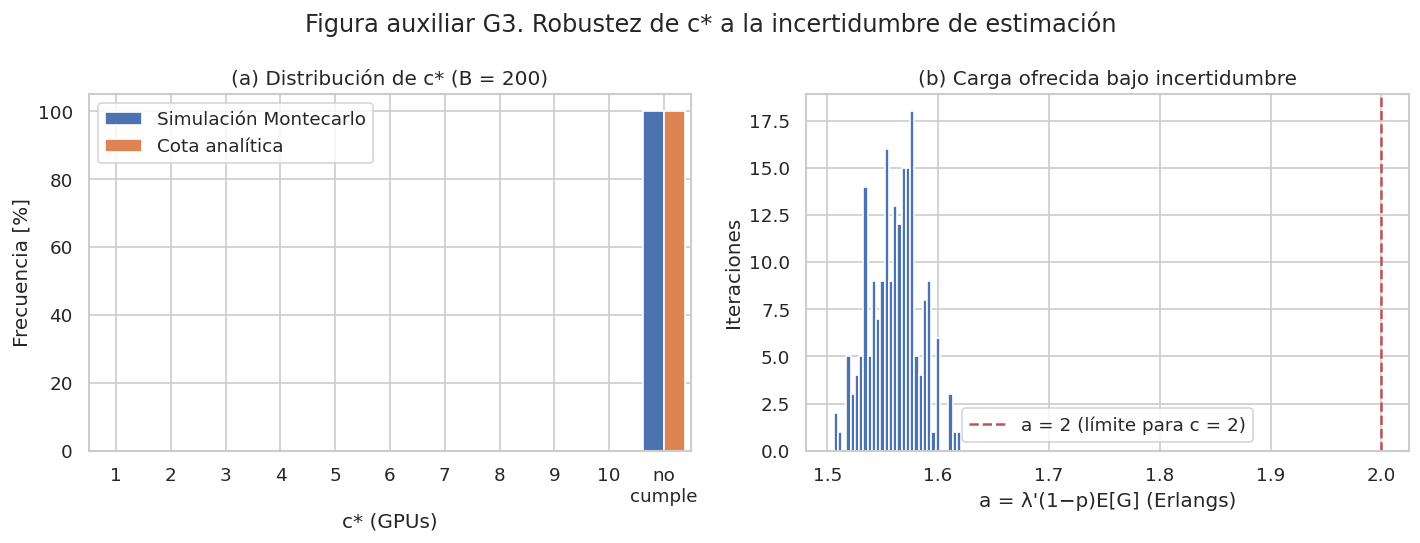

In [48]:
# Figura auxiliar G3
NO_CUMPLE = 11            # <-- c_max + 1 de tus funciones (el valor que devuelven cuando ninguna c cumple)

# Diagnóstico rápido
print("c* simulación:", dict(zip(*np.unique(c_sim, return_counts=True))))
print("c* analítico :", dict(zip(*np.unique(c_ana, return_counts=True))))

vals = np.arange(1, max(c_sim.max(), c_ana.max(), 3) + 1)      # cubre todos los valores observados
etiquetas = ["no\ncumple" if v == NO_CUMPLE else str(v) for v in vals]

fig, ax = plt.subplots(1, 2, figsize=(12, 4.6))
w = 0.38
ax[0].bar(vals - w / 2, [100 * np.mean(c_sim == v) for v in vals], w, label="Simulación Montecarlo")
ax[0].bar(vals + w / 2, [100 * np.mean(c_ana == v) for v in vals], w, label="Cota analítica")
ax[0].set_xlim(0.5, vals[-1] + 0.5)
ax[0].set_xticks(vals)
ax[0].set_xticklabels(etiquetas)
ax[0].set_ylim(0, 105)
ax[0].set(title=f"(a) Distribución de c* (B = {B_G3})", xlabel="c* (GPUs)", ylabel="Frecuencia [%]")
ax[0].legend()

ax[1].hist(a_draws, bins=30)
ax[1].axvline(2, color="r", ls="--", label="a = 2 (límite para c = 2)")
ax[1].set(title="(b) Carga ofrecida bajo incertidumbre", xlabel="a = λ'(1−p)E[G] (Erlangs)", ylabel="Iteraciones")
ax[1].legend()

fig.suptitle("Figura auxiliar G3. Robustez de c* a la incertidumbre de estimación")
fig.tight_layout()
fig.savefig("figura_G3_robustez.png", dpi=200, bbox_inches="tight")
plt.show()

**G4.**

In [47]:
# G4. Cifras para el memorando ejecutivo (cada número del PDF sale de esta celda o de las Partes A-F)
resumen_memo = {
    "tau_ms": TAU, "eps": EPS, "g": G_CREC, "confianza": CONF,
    "lambda_estable_sol_s": est["lam"], "p_cache": est["p_cache"], "E_G_ms": EG,
    "P_viol_actual_sim_%": 100 * p_sim[0], "P_viol_actual_real_%": 100 * REAL["p_viol"],
    "carga_a_Erlangs_g": a_carga, "c_min_estable": c_min_estable,
    "c_estrella": c_estrella, "c_robusto_IC": c_robusto,
    "c_95%_sim": c_rob_sim, "c_95%_cota_analitica": c_rob_ana,
}
for k, v in resumen_memo.items():
    print(f"{k:>24}: {v:.4f}" if isinstance(v, float) else f"{k:>24}: {v}")


                  tau_ms: 230
                     eps: 0.0300
                       g: 2.0000
               confianza: 0.9900
    lambda_estable_sol_s: 15.0000
                 p_cache: 0.3500
                  E_G_ms: 80.0000
     P_viol_actual_sim_%: 6.8631
    P_viol_actual_real_%: 2.0000
       carga_a_Erlangs_g: 1.5600
           c_min_estable: 2
              c_estrella: None
            c_robusto_IC: None
               c_95%_sim: 11
    c_95%_cota_analitica: 11
